# Gestion de stock : quels produits réapprovisionner ?

**Problème :** Identifier les produits sous le seuil d'alerte et estimer la valeur du stock. Anomalies : stock négatif, prix nul.

Les données sont synthétiques. Exécute les cellules dans l'ordre. Le fichier `donnees.xlsx` doit rester dans le même dossier que ce notebook.

## Étape 1 — Lire et explorer les données

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
df = pd.read_excel("donnees.xlsx", sheet_name="donnees")
print("Dimensions :", df.shape)
display(df.head())
display(df.sample(min(5, len(df)), random_state=1))


Dimensions : (30, 6)


,reference,produit,categorie,stock,seuil_alerte,prix_mad
0,P001,Cahier,Papeterie,10,17,15
1,P002,Calculatrice,Électronique,18,17,120
2,P003,Calculatrice,Électronique,40,23,120
3,P004,Cahier,Papeterie,46,19,15
4,P005,Classeur,Papeterie,56,22,22


,reference,produit,categorie,stock,seuil_alerte,prix_mad
17,P018,Sac,Accessoires,3,21,180
21,P022,Stylo,Papeterie,72,24,5
10,P011,Classeur,Papeterie,0,17,22
19,P020,Stylo,Papeterie,45,14,5
14,P015,Calculatrice,Électronique,15,11,120


## Étape 2 — Comprendre la structure

In [11]:
df.info()
display(df.describe(include="all").T)
print("Colonnes :", df.columns.tolist())


<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   reference     30 non-null     str  
 1   produit       30 non-null     str  
 2   categorie     30 non-null     str  
 3   stock         30 non-null     int64
 4   seuil_alerte  30 non-null     int64
 5   prix_mad      30 non-null     int64
dtypes: int64(3), str(3)
memory usage: 1.5 KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
reference,30,30,P001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
produit,30,5,Classeur,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
categorie,30,3,Papeterie,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stock,30.0,NaN,NaN,NaN,35.166667,23.543186,-3.0,15.75,36.5,53.5,77.0
seuil_alerte,30.0,NaN,NaN,NaN,16.9,4.221047,10.0,14.0,17.0,20.75,24.0
prix_mad,30.0,NaN,NaN,NaN,56.8,65.363915,0.0,7.5,22.0,120.0,180.0


Colonnes : ['reference', 'produit', 'categorie', 'stock', 'seuil_alerte', 'prix_mad']


## Étape 3 — Détecter les anomalies

In [3]:
print("Valeurs manquantes :")
display(df.isna().sum())
print("Lignes dupliquées :", df.duplicated().sum())
for col in df.select_dtypes(include=["object", "string"]).columns:
    print(f"\\n{col} :", df[col].dropna().astype(str).unique()[:15])


Valeurs manquantes :


reference       0
produit         0
categorie       0
stock           0
seuil_alerte    0
prix_mad        0
dtype: int64

Lignes dupliquées : 0
\nreference : <StringArray>
['P001', 'P002', 'P003', 'P004', 'P005', 'P006', 'P007', 'P008', 'P009',
 'P010', 'P011', 'P012', 'P013', 'P014', 'P015']
Length: 15, dtype: str
\nproduit : <StringArray>
['Cahier', 'Calculatrice', 'Classeur', 'Stylo', 'Sac']
Length: 5, dtype: str
\ncategorie : <StringArray>
['Papeterie', 'Électronique', 'Accessoires']
Length: 3, dtype: str


## Étape 4 — Nettoyer les données

On conserve `df` intact et on travaille sur une copie `df_clean`. Adapte les règles selon le problème métier.

In [4]:
df_clean = df.copy()
df_clean = df_clean.drop_duplicates()

# Nettoyage simple des espaces dans les colonnes texte
for col in df_clean.select_dtypes(include=["object", "string"]).columns:
    df_clean[col] = df_clean[col].astype("string").str.strip()

df_clean["produit"] = df_clean["produit"].str.title()

print("Dimensions après nettoyage :", df_clean.shape)
display(df_clean.head())

Dimensions après nettoyage : (30, 6)


,reference,produit,categorie,stock,seuil_alerte,prix_mad
0,P001,Cahier,Papeterie,10,17,15
1,P002,Calculatrice,Électronique,18,17,120
2,P003,Calculatrice,Électronique,40,23,120
3,P004,Cahier,Papeterie,46,19,15
4,P005,Classeur,Papeterie,56,22,22


## Étape 5 — Analyse avec Pandas et calculs NumPy

In [5]:
for col in ["stock","seuil_alerte","prix_mad"]:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")
df_analyse = df_clean[(df_clean["stock"] >= 0) & (df_clean["prix_mad"] > 0)].copy()
df_analyse["valeur_stock"] = df_analyse["stock"] * df_analyse["prix_mad"]
df_analyse["alerte"] = df_analyse["stock"] < df_analyse["seuil_alerte"]
display(df_analyse[["produit","stock","seuil_alerte","valeur_stock","alerte"]].sort_values("alerte",ascending=False))
print("Valeur totale du stock :", np.sum(df_analyse["valeur_stock"]))


,produit,stock,seuil_alerte,valeur_stock,alerte
0,Cahier,10,17,150,True
17,Sac,3,21,540,True
26,Sac,14,21,2520,True
24,Calculatrice,4,17,480,True
23,Cahier,5,20,75,True
10,Classeur,0,17,0,True
28,Cahier,67,14,1005,False
27,Cahier,68,15,1020,False
25,Classeur,29,11,638,False
22,Sac,36,20,6480,False


Valeur totale du stock : 40624


## Étape 6 — Visualisation avec Matplotlib

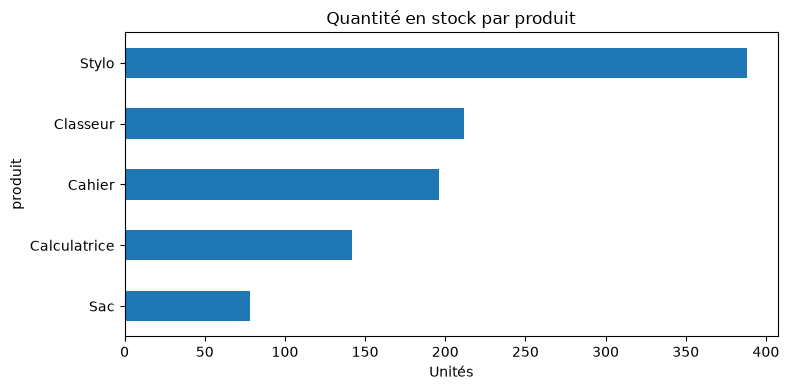

In [6]:
df_analyse.groupby("produit")["stock"].sum().sort_values().plot(kind="barh", figsize=(8,4))
plt.title("Quantité en stock par produit")
plt.xlabel("Unités")
plt.tight_layout()
plt.show()


## Exporter le résultat nettoyé

In [7]:
df_clean.to_csv("donnees_nettoyees.csv", index=False, encoding="utf-8-sig")
df_clean.to_excel("donnees_nettoyees.xlsx", index=False)
print("Export terminé.")


Export terminé.
